
# Yambda 17 · Improving the ranker: organic features, BPR candidates, new-artist weighting

Same protocol as notebook 16: ranker trained on the earlier window (`split_rank`, labels days 259–273),
evaluated on validation (days 273–287). Three changes, tested one after another:

| Step | Change | Why |
|---|---|---|
| B | + organic features: user's organic share, track's organic share, organic listeners last 7d, skip rate | the target *is* organic discovery |
| C | + BPR as a fourth candidate source (top 100) | BPR is the strongest single model on new artists |
| D | graded labels: a new-artist discovery counts `w` times a familiar one (LambdaRank `label_gain`) | the current ranker only improves familiar artists |

**Decision rule for D, fixed before looking:** pick the largest `w` whose overall validation recall@10 stays
within 5% of `w = 1`.

First run ≈ 40 min (BPR and iALS on two windows; candidates are cached to `data/processed/yambda/cands/`).


In [1]:

import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from musicrec import config
from musicrec.preprocess import Split
from musicrec.evaluation import evaluate, paired_bootstrap, artist_novelty
from musicrec.yambda import load_item_artist, build_events
from musicrec.models.baselines import MostPopular
from musicrec.models.als import IALS
from musicrec.models.bpr import BPR
from musicrec import ranking as R

pd.set_option("display.float_format", "{:,.4f}".format)
OUT = config.PROJECT_ROOT / "reports" / "yambda"
CACHE = config.YAMBDA_DIR / "cands"; CACHE.mkdir(parents=True, exist_ok=True)
K = {"ials": 200, "sasrec": 200, "pop": 100, "bpr": 100}
S3, S4 = ["ials", "sasrec", "pop"], ["ials", "sasrec", "pop", "bpr"]
item_artist = load_item_artist()
ials_params = json.loads((OUT / "best_ials.json").read_text())["params"]
bpr_cfg = json.loads((OUT / "best_bpr.json").read_text())
events = build_events(min_played_ratio=50)          # raw events, needed for the organic features


In [2]:

def source_cands(tag, split, src, sasrec_file):
    """Top-K list of one source on one split, cached as parquet (no labels involved)."""
    path = CACHE / f"{tag}_{src}.parquet"
    if path.exists():
        return pd.read_parquet(path)
    t = time.time()
    if src == "sasrec":
        df = pd.read_parquet(OUT / sasrec_file)
    else:
        model = {"ials": lambda: IALS(**ials_params),
                 "pop": lambda: MostPopular(by="listeners", recent_days=7),
                 "bpr": lambda: BPR(**bpr_cfg["params"], epochs=bpr_cfg["best_epoch"], early_stopping=False)}[src]()
        model.fit(split) if src != "bpr" else model.fit(split, verbose=False)
        df = R.candidates_from_model(model, split, K[src])
    df = df[df["rank"] <= K[src]]
    df.to_parquet(path, index=False)
    print(f"  {tag}/{src}: {len(df):,} rows ({time.time() - t:.0f}s)")
    return df

def build(tag, split, sasrec_file, sources):
    src = {s: source_cands(tag, split, s, sasrec_file) for s in sources}
    c = R.add_labels(R.merge_candidates(src), split)
    c = R.add_features(c, split, item_artist, sources)
    c = R.add_organic_features(c, split, events)
    c["rrf"] = R.rrf_scores(c, sources)
    c["rel"] = R.graded_relevance(c)
    return c

def evaluate_col(c, split, col, name, new_artist):
    m = R.PrecomputedScores(c[["user_idx", "item_idx", col]].dropna(), split.n_items, name, col)
    r = evaluate(m, split, return_per_user=True)
    r["recall@10 | new-artist"] = evaluate(m, split, targets=split.targets[new_artist])["recall@10"]
    r["recall@10 | known-artist"] = evaluate(m, split, targets=split.targets[~new_artist])["recall@10"]
    return r

def table(res):
    return pd.DataFrame({n: {k: v for k, v in r.items() if k != "per_user"} for n, r in res.items()}).T[
        ["recall@10", "recall@10 | known-artist", "recall@10 | new-artist", "hit_rate@10", "coverage@10", "avg_pop@10"]]


## Candidates for the ranker-training window and validation

In [3]:

rank = Split.load(config.YAMBDA_SPLIT_RANK_DIR)
val = Split.load(config.YAMBDA_SPLIT_VAL_DIR)
c3_rank, c4_rank = build("rank", rank, "cands_rank_sasrec.parquet", S3), build("rank", rank, "cands_rank_sasrec.parquet", S4)
c3_val, c4_val = build("val", val, "cands_val_sasrec.parquet", S3), build("val", val, "cands_val_sasrec.parquet", S4)
new_artist_val = artist_novelty(val, item_artist)
pd.DataFrame({"3 sources": R.candidate_recall(c3_val, val, S3), "4 sources (+BPR)": R.candidate_recall(c4_val, val, S4)})


  val/bpr: 567,800 rows (787s)


,3 sources,4 sources (+BPR)
bpr,NaN,0.0666
candidates per user,424.2017,459.0231
ials,0.1239,0.1239
pop,0.0445,0.0445
sasrec,0.0931,0.0931
union,0.1852,0.1956


## Steps A–C

In [4]:

BASE3, ORG3, ORG4 = R.feature_columns(S3), R.feature_columns(S3, organic=True), R.feature_columns(S4, organic=True)
res, rankers = {}, {}
res["iALS alone"] = evaluate_col(c3_val, val, "score_ials", "iALS alone", new_artist_val)

for name, c_tr, c_ev, feats in [("A  3 sources, base features", c3_rank, c3_val, BASE3),
                                ("B  + organic features",       c3_rank, c3_val, ORG3),
                                ("C  + BPR candidates",          c4_rank, c4_val, ORG4)]:
    rankers[name] = R.fit_ranker(c_tr, feats)
    c_ev[name] = rankers[name].predict(c_ev[feats])
    res[name] = evaluate_col(c_ev, val, name, name, new_artist_val)
    print(f"{name:<32} recall@10={res[name]['recall@10']:.4f}  new-artist={res[name]['recall@10 | new-artist']:.4f}")
table(res)


A  3 sources, base features      recall@10=0.0455  new-artist=0.0161
B  + organic features            recall@10=0.0509  new-artist=0.0165
C  + BPR candidates              recall@10=0.0524  new-artist=0.0186


,recall@10,recall@10 | known-artist,recall@10 | new-artist,hit_rate@10,coverage@10,avg_pop@10
iALS alone,0.0346,0.0410,0.0160,0.1671,0.0549,832.0774
"A 3 sources, base features",0.0455,0.0590,0.0161,0.2138,0.0616,720.7965
B + organic features,0.0509,0.0667,0.0165,0.2277,0.0568,681.4136
C + BPR candidates,0.0524,0.0674,0.0186,0.2319,0.0558,656.6709


In [5]:

pd.DataFrame({
    "B vs A (organic features)": paired_bootstrap(res["A  3 sources, base features"]["per_user"], res["B  + organic features"]["per_user"]),
    "C vs B (BPR candidates)":   paired_bootstrap(res["B  + organic features"]["per_user"], res["C  + BPR candidates"]["per_user"]),
    "C vs iALS":                 paired_bootstrap(res["iALS alone"]["per_user"], res["C  + BPR candidates"]["per_user"]),
}).T[["a", "b", "diff", "rel_diff", "ci_low", "ci_high", "p(b<=a)"]]


,a,b,diff,rel_diff,ci_low,ci_high,p(b<=a)
B vs A (organic features),0.0455,0.0509,0.0054,0.1190,0.0031,0.0077,0.0000
C vs B (BPR candidates),0.0509,0.0524,0.0015,0.0299,-0.0007,0.0038,0.0885
C vs iALS,0.0346,0.0524,0.0178,0.5145,0.0146,0.0211,0.0000


In [6]:

# Which configuration goes into step D: the best of A-C on overall validation recall
best_step = max(["A  3 sources, base features", "B  + organic features", "C  + BPR candidates"], key=lambda n: res[n]["recall@10"])
CFG = {"A  3 sources, base features": (c3_rank, c3_val, BASE3, S3),
       "B  + organic features":       (c3_rank, c3_val, ORG3, S3),
       "C  + BPR candidates":          (c4_rank, c4_val, ORG4, S4)}[best_step]
print("step D builds on:", best_step)
imp = pd.Series(rankers[best_step].booster_.feature_importance("gain"), index=CFG[2])
(imp / imp.sum()).sort_values(ascending=False).round(3).head(12)


step D builds on: C  + BPR candidates


item_age_days               0.1120
user_artist_plays           0.0900
rank_ials                   0.0830
item_organic_share          0.0670
n_sources                   0.0660
score_pop                   0.0600
item_trend                  0.0570
item_organic_listeners_7d   0.0470
user_artist_plays_7d        0.0460
score_ials                  0.0360
artist_pop_7d               0.0360
item_skip_rate              0.0340
dtype: float64

## Step D: weighting new-artist discoveries

In [7]:

c_tr, c_ev, feats, _ = CFG
sweep = {}
for w in [1, 2, 4, 8, 16]:
    m = R.fit_ranker(c_tr, feats, label_col="rel", label_gain=[0, 1, w])
    col = f"w{w}"
    c_ev[col] = m.predict(c_ev[feats])
    r = evaluate_col(c_ev, val, col, f"w={w}", new_artist_val)
    sweep[w] = r
    print(f"w={w:<3} recall@10={r['recall@10']:.4f}  new-artist={r['recall@10 | new-artist']:.4f}  known-artist={r['recall@10 | known-artist']:.4f}")
sw = table({f"w={w}": r for w, r in sweep.items()})
sw


w=1   recall@10=0.0524  new-artist=0.0186  known-artist=0.0674
w=2   recall@10=0.0532  new-artist=0.0244  known-artist=0.0601
w=4   recall@10=0.0495  new-artist=0.0283  known-artist=0.0489
w=8   recall@10=0.0498  new-artist=0.0346  known-artist=0.0427
w=16  recall@10=0.0458  new-artist=0.0332  known-artist=0.0368


,recall@10,recall@10 | known-artist,recall@10 | new-artist,hit_rate@10,coverage@10,avg_pop@10
w=1,0.0524,0.0674,0.0186,0.2319,0.0558,656.6709
w=2,0.0532,0.0601,0.0244,0.2279,0.0521,690.6390
w=4,0.0495,0.0489,0.0283,0.2152,0.0478,745.0609
w=8,0.0498,0.0427,0.0346,0.2212,0.0478,730.4096
w=16,0.0458,0.0368,0.0332,0.2101,0.0431,824.1709


chosen w = 2  (overall 0.0532 vs 0.0524 at w=1; new-artist 0.0244 vs 0.0186)


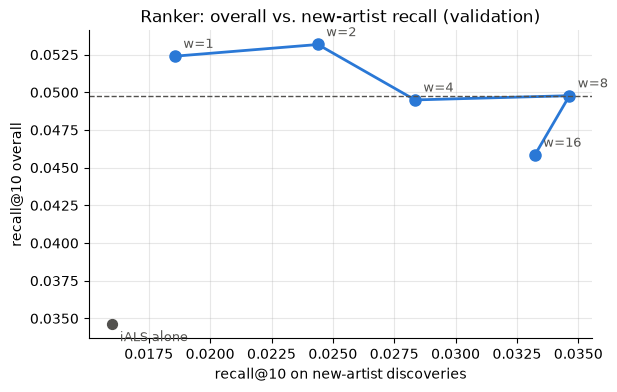

In [8]:

base_recall = sweep[1]["recall@10"]
ok = [w for w, r in sweep.items() if r["recall@10"] >= 0.95 * base_recall]
W = max(ok)
print(f"chosen w = {W}  (overall {sweep[W]['recall@10']:.4f} vs {base_recall:.4f} at w=1; "
      f"new-artist {sweep[W]['recall@10 | new-artist']:.4f} vs {sweep[1]['recall@10 | new-artist']:.4f})")

BLUE, GRAY = "#2a78d6", "#52514e"
fig, ax = plt.subplots(figsize=(6.5, 4))
xs = [r["recall@10 | new-artist"] for r in sweep.values()]
ys = [r["recall@10"] for r in sweep.values()]
ax.plot(xs, ys, color=BLUE, lw=2, marker="o", markersize=8)
for w, x, y in zip(sweep, xs, ys):
    ax.annotate(f"w={w}", (x, y), textcoords="offset points", xytext=(6, 6), color=GRAY, fontsize=9)
ia = res["iALS alone"]
ax.scatter([ia["recall@10 | new-artist"]], [ia["recall@10"]], color=GRAY, s=50, zorder=3)
ax.annotate("iALS alone", (ia["recall@10 | new-artist"], ia["recall@10"]), textcoords="offset points", xytext=(6, -12), color=GRAY, fontsize=9)
ax.axhline(0.95 * base_recall, color=GRAY, lw=1, ls="--")
ax.set(xlabel="recall@10 on new-artist discoveries", ylabel="recall@10 overall",
       title="Ranker: overall vs. new-artist recall (validation)")
ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.3)
fig.savefig(config.YAMBDA_FIGURES_DIR / "y17_new_artist_tradeoff.png", dpi=150, bbox_inches="tight")


In [9]:

pd.concat([table(res), sw]).to_csv(OUT / "ranker_v2_val.csv")
pd.Series(paired_bootstrap(sweep[1]["per_user"], sweep[W]["per_user"]), name=f"w={W} vs w=1 (overall recall@10)")


a           0.0524
b           0.0532
diff        0.0008
rel_diff    0.0148
ci_low     -0.0016
ci_high     0.0030
p(b<=a)     0.2655
Name: w=2 vs w=1 (overall recall@10), dtype: float64


## Test (run once, after we agree on the validation result)

Ranker retrained on the validation window with the chosen configuration and `w`, applied to test.
Compared with iALS and with the two-stage ranker from notebook 16 (3 sources, base features, `w = 1`).


In [11]:

RUN_TEST = True
if RUN_TEST:
    test = Split.load(config.YAMBDA_SPLIT_TEST_DIR)
    _, _, feats, sources = CFG
    c_test = build("test", test, "cands_test_sasrec.parquet", sources)
    c3_test = c_test if sources == S3 else build("test", test, "cands_test_sasrec.parquet", S3)
    na_test = artist_novelty(test, item_artist)

    old = R.fit_ranker(c3_val, BASE3)                                         # notebook-16 ranker
    c3_test["old"] = old.predict(c3_test[BASE3])
    new_w1 = R.fit_ranker(c_ev, feats)
    c_test["new_w1"] = new_w1.predict(c_test[feats])
    new_w = R.fit_ranker(c_ev, feats, label_col="rel", label_gain=[0, 1, W])
    c_test["new_w"] = new_w.predict(c_test[feats])

    res_t = {"iALS alone": evaluate_col(c3_test, test, "score_ials", "iALS", na_test),
             "Two-stage v1 (notebook 16)": evaluate_col(c3_test, test, "old", "v1", na_test),
             f"Two-stage v2, {best_step.strip()}": evaluate_col(c_test, test, "new_w1", "v2", na_test),
             f"Two-stage v2, w={W}": evaluate_col(c_test, test, "new_w", "v2w", na_test)}
    names = list(res_t)
    sig_t = pd.DataFrame({f"{n} vs {names[1]}": paired_bootstrap(res_t[names[1]]["per_user"], res_t[n]["per_user"]) for n in names[2:]}).T
    table(res_t).to_csv(OUT / "final_test_ranker_v2.csv"); sig_t.to_csv(OUT / "final_test_ranker_v2_significance.csv")
    display(table(res_t), sig_t[["a", "b", "diff", "rel_diff", "ci_low", "ci_high", "p(b<=a)"]])


  test/ials: 1,261,200 rows (234s)
  test/sasrec: 1,261,200 rows (1s)
  test/pop: 630,600 rows (36s)
  test/bpr: 630,600 rows (725s)


,recall@10,recall@10 | known-artist,recall@10 | new-artist,hit_rate@10,coverage@10,avg_pop@10
iALS alone,0.0334,0.0382,0.0169,0.1514,0.0564,882.0132
Two-stage v1 (notebook 16),0.0490,0.0662,0.0157,0.2090,0.0699,663.2747
"Two-stage v2, C + BPR candidates",0.0529,0.0694,0.0185,0.2225,0.0615,640.7778
"Two-stage v2, w=2",0.0489,0.0574,0.0220,0.2111,0.0622,688.8245


,a,b,diff,rel_diff,ci_low,ci_high,p(b<=a)
"Two-stage v2, C + BPR candidates vs Two-stage v1 (notebook 16)",0.0490,0.0529,0.0039,0.0799,0.0015,0.0063,0.0015
"Two-stage v2, w=2 vs Two-stage v1 (notebook 16)",0.0490,0.0489,-0.0001,-0.0019,-0.0026,0.0024,0.5305
